# Customer Churn Analysis

## Project Overview

Customer churn is one of the major challenges faced by subscription-based businesses. It refers to the situation in which customers discontinue their subscriptions or stop using a company's services.

This project focuses on analyzing customer churn patterns to understand why customers leave, which customer segments experience higher churn, and how businesses can improve customer retention.

Using Python, SQL, Pandas, NumPy, Matplotlib, and Seaborn, this project explores customer demographics, subscription details, monthly charges, and customer support interactions to identify meaningful patterns and business insights.

## Project Objectives

- Calculate the overall customer churn and retention rates.
- Identify customer segments with higher churn rates.
- Analyze churn across subscription plans, contract types, and geographical locations.
- Evaluate customer revenue, average revenue per user (ARPU), and revenue at risk.
- Examine the relationship between customer support interactions, escalations, and churn.
- Visualize important trends and relationships using statistical charts.
- Generate actionable business recommendations to improve customer retention.

## Dataset Description

The analysis uses three interconnected datasets:

1. **Customer Data:** Contains customer information such as customer ID, name, gender, date of birth, state, and country.
2. **Subscription Data:** Contains subscription type, plan type, contract details, monthly charges, renewal dates, cancellation dates, and churn-related information.
3. **Customer Support Data:** Contains complaint dates, escalation records, CSAT scores, and customer comments.

The datasets are connected using the common `customerid` field.

## Tools and Technologies

- Python – Data analysis and manipulation
- Pandas & NumPy – Data cleaning, transformation, and calculations
- SQLite – Database connectivity and data extraction
- Matplotlib & Seaborn – Data visualization
- Jupyter Notebook – Interactive analysis and documentation

## Project Methodology

The project follows a structured data analytics workflow:

1. Data extraction from the SQLite database.
2. Data inspection and understanding.
3. Data cleaning and preprocessing.
4. Feature engineering and customer-level data aggregation.
5. Dataset integration using customer IDs.
6. Exploratory Data Analysis (EDA).
7. Statistical analysis and data visualization.
8. Interpretation of findings and business recommendations.

## Expected Outcome

The objective is to transform raw customer, subscription, and support data into meaningful insights that help understand churn behavior, identify at-risk customer segments, and support data-driven retention strategies.

## 1. Importing Libraries

In this section, we import the Python libraries required for data manipulation, numerical operations, database connectivity, and data visualization.


In [1]:
# Importing required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sqlite3
import seaborn as sns


## 2. Database Connection & Data Loading

In this section, we establish a connection with the SQLite database and retrieve the available tables into Pandas DataFrames.

This allows us to work with customer, subscription, and support data directly in Python.


In [2]:

# Connecting to the SQLite database

connection = sqlite3.connect('customer_churn_analysis.db')

# Fetching available table names
sql_query = """
    SELECT name
    FROM sqlite_master
    WHERE type = 'table'
"""

tables = pd.read_sql(sql_query, connection)

# Loading tables into separate DataFrames
for table_name in tables['name']:
    df_table = pd.read_sql(f"SELECT * FROM {table_name}", connection)
    globals()[f"df_{table_name}"] = df_table

    print(f"{table_name}: {df_table.shape}")

connection.close()


db_customer: (5000, 8)
db_subscription: (5000, 11)
db_support: (10563, 6)


## 3. Data Understanding & Initial Inspection

Before performing data cleaning and analysis, we inspect the structure of each dataset.

This includes checking the number of records, column names, data types, and sample records to understand the data and identify potential issues.

In [3]:
# Checking the structure of customer data

print("Customer Data:")
print(df_db_customer.info())

print("\nSubscription Data:")
print(df_db_subscription.info())

print("\nSupport Data:")
print(df_db_support.info())

Customer Data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   customerid  5000 non-null   object 
 1   name        5000 non-null   object 
 2   country     4840 non-null   object 
 3   state       5000 non-null   object 
 4   gender      5000 non-null   object 
 5   dob         5000 non-null   object 
 6   interests   1114 non-null   object 
 7   pincode     4404 non-null   float64
dtypes: float64(1), object(7)
memory usage: 312.6+ KB
None

Subscription Data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customerid               5000 non-null   object 
 1   subscription_start_date  5000 non-null   object 
 2   subscription_type        5000 non-null   object 
 3   renewal_

## 2. Data Cleaning

### A. Customer Data Cleaning

Before cleaning the customer dataset, we inspect the first and last few records to understand the existing data.

In [4]:
# Checking first 5 records
df_db_customer.head()

,customerid,name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00,travel,NaN
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00,None,NaN
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00,movie,NaN
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00,None,NaN
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00,drama,NaN


In [5]:
df_db_customer.tail()

,customerid,name,country,state,gender,dob,interests,pincode
4995,9986-IGJVG,sanjay,India,Punjab,Male,1991-04-30 00:00:00,None,142235.0
4996,9986-MTVDR,karan,India,Gujarat,Male,1989-04-08 00:00:00,None,372560.0
4997,9992-ELMRV,om,India,Odisha,Male,1978-04-01 00:00:00,kids,763182.0
4998,9994-ECAVK,eshan,India,Karnataka,Male,1994-05-13 00:00:00,None,572266.0
4999,9998-JTGPH,ankit,India,Haryana,Male,1983-08-17 00:00:00,None,124188.0


In [6]:
# A. RENAME COLUMN - NAME
# B. DROP COLUMNS -INTEREST AND PINCODE 
# C. CHANGE DATATYPE - DOB
# D. DATA STANDARDIZATION
# E. FIX MISSING VALUE - COUNTRY

### A. Rename Column – Name

The `name` column in the customer dataset is renamed to `customer_name` to make the column name more descriptive and consistent with the analysis.

In [7]:
# Renaming name column

df_db_customer.rename(columns={'name': 'customer_name'}, inplace=True)

df_db_customer.head()

,customerid,customer_name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00,travel,NaN
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00,None,NaN
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00,movie,NaN
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00,None,NaN
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00,drama,NaN


### B. Drop Columns – Interests and Pincode

The `interests` and `pincode` columns are removed from the customer dataset as they are not required for the current churn analysis.

In [8]:
# Dropping unnecessary columns

df_db_customer.drop(df_db_customer.columns[-2:],axis=1, inplace = True)

df_db_customer.head()

,customerid,customer_name,country,state,gender,dob
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00


### C. Change Datatype – DOB

The `dob` column is converted from object datatype to datetime format. This allows us to perform date-based operations and calculations during analysis.

In [9]:
# Converting DOB column to datetime

df_db_customer['dob'] = pd.to_datetime(df_db_customer['dob'])

df_db_customer.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   customerid     5000 non-null   object        
 1   customer_name  5000 non-null   object        
 2   country        4840 non-null   object        
 3   state          5000 non-null   object        
 4   gender         5000 non-null   object        
 5   dob            5000 non-null   datetime64[ns]
dtypes: datetime64[ns](1), object(5)
memory usage: 234.5+ KB


### D. Data Standardization

The gender column is checked for unique values to identify inconsistent naming conventions. The values `Men` and `Women` are standardized to `Male` and `Female` respectively.

In [10]:
# Checking unique gender values

df_db_customer['gender'].unique()

array(['Male', 'Female', 'Women', 'Men'], dtype=object)

In [11]:
# Standardizing gender values

df_db_customer['gender'] = df_db_customer['gender'].replace({
    'Men':'Male' , 
    'Women' : 'Female'})

# Verifying standardized values

df_db_customer['gender'].unique()

array(['Male', 'Female'], dtype=object)

### E. Fix Missing Values – Country

The country column is checked for missing values. We use the existing state and country relationships to fill missing country values wherever a reliable mapping is available.

To identify the relationship between states and countries, we create a mapping using records where the country value is already available. This mapping will be used to fill missing country values.

In [12]:
# Checking rows where country is missing

df_db_customer[df_db_customer['country'].isna()]


# Creating state-country mapping

state_country_mapping = df_db_customer.dropna(subset=['country']).set_index('state')['country'].to_dict()

# Filling missing country values using state-country mapping

df_db_customer['country'] = df_db_customer['country'].fillna(df_db_customer['state'].map(state_country_mapping))

# Checking remaining missing country values
df_db_customer[df_db_customer['country'].isna()][['customer_name', 'state']]


,customer_name,state


### B. Subscription Data Cleaning

We inspect the subscription dataset to understand its structure, available columns, and existing records before performing data cleaning.

In [13]:
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,None,None,13.99,627,12
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,None,None,6.99,210,34
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,None,None,22.99,1725,8
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88


The dataset information is inspected to identify column data types, non-null values, and missing records before converting date columns.

In [14]:
# Checking subscription dataset information

df_db_subscription.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customerid               5000 non-null   object 
 1   subscription_start_date  5000 non-null   object 
 2   subscription_type        5000 non-null   object 
 3   renewal_date             5000 non-null   object 
 4   plan_type                5000 non-null   object 
 5   contract_type            5000 non-null   object 
 6   cancellation_date        1386 non-null   object 
 7   cancellation_reason      1345 non-null   object 
 8   monthly_charges          5000 non-null   float64
 9   cltv                     5000 non-null   int64  
 10  churn_score              5000 non-null   int64  
dtypes: float64(1), int64(2), object(8)
memory usage: 429.8+ KB


In [15]:
date_col = ['subscription_start_date', 'renewal_date','cancellation_date']
df_db_subscription[date_col] = df_db_subscription[date_col].apply(pd.to_datetime)
df_db_subscription.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               5000 non-null   object        
 1   subscription_start_date  5000 non-null   datetime64[ns]
 2   subscription_type        5000 non-null   object        
 3   renewal_date             5000 non-null   datetime64[ns]
 4   plan_type                5000 non-null   object        
 5   contract_type            5000 non-null   object        
 6   cancellation_date        1386 non-null   datetime64[ns]
 7   cancellation_reason      1345 non-null   object        
 8   monthly_charges          5000 non-null   float64       
 9   cltv                     5000 non-null   int64         
 10  churn_score              5000 non-null   int64         
dtypes: datetime64[ns](3), float64(1), int64(2), object(5)
memory usage: 429.8+ KB


### C. Change Datatype – Subscription Dates

The subscription start date, renewal date, and cancellation date columns are converted into datetime format to enable date-based analysis.

In [16]:
# Converting date columns to datetime

date_col = ['subscription_start_date', 'renewal_date','cancellation_date']

df_db_subscription[date_col] = df_db_subscription[date_col].apply(pd.to_datetime)

df_db_subscription.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               5000 non-null   object        
 1   subscription_start_date  5000 non-null   datetime64[ns]
 2   subscription_type        5000 non-null   object        
 3   renewal_date             5000 non-null   datetime64[ns]
 4   plan_type                5000 non-null   object        
 5   contract_type            5000 non-null   object        
 6   cancellation_date        1386 non-null   datetime64[ns]
 7   cancellation_reason      1345 non-null   object        
 8   monthly_charges          5000 non-null   float64       
 9   cltv                     5000 non-null   int64         
 10  churn_score              5000 non-null   int64         
dtypes: datetime64[ns](3), float64(1), int64(2), object(5)
memory usage: 429.8+ KB


### C. Support Data Cleaning

We inspect the support dataset to understand its structure, available columns, and existing records before performing data cleaning.

In [17]:
# Checking first 5 records

df_db_support.head()

,customerid,complaint_date,escalations,csat_score,col_1,comment
0,0003-MKNFE,2024-08-28 00:00:00,N,60.0,None,service issue
1,0003-MKNFE,2024-08-28 00:00:00,Y,10.0,None,demaned refund
2,0013-EXCHZ,2024-01-20 00:00:00,Y,20.0,None,None
3,0013-MHZWF,2025-03-18 00:00:00,N,90.0,None,guidance to renew
4,0013-SMEOE,2024-11-01 00:00:00,N,30.0,None,None


The support dataset information is inspected to identify column data types, non-null values, and missing records before performing data cleaning.

In [18]:
# Checking support dataset information

df_db_support.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10563 entries, 0 to 10562
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   customerid      10563 non-null  object 
 1   complaint_date  10563 non-null  object 
 2   escalations     10563 non-null  object 
 3   csat_score      10247 non-null  float64
 4   col_1           0 non-null      object 
 5   comment         7167 non-null   object 
dtypes: float64(1), object(5)
memory usage: 495.3+ KB


### A. Remove Unnecessary Column

The `col_1` column is removed because it contains no valid records. The `comment` column is retained as it contains customer feedback that may be useful for further analysis.

In [19]:
# Dropping completely empty column

df_db_support.drop(columns=['col_1'], inplace=True)

df_db_support.head()

,customerid,complaint_date,escalations,csat_score,comment
0,0003-MKNFE,2024-08-28 00:00:00,N,60.0,service issue
1,0003-MKNFE,2024-08-28 00:00:00,Y,10.0,demaned refund
2,0013-EXCHZ,2024-01-20 00:00:00,Y,20.0,None
3,0013-MHZWF,2025-03-18 00:00:00,N,90.0,guidance to renew
4,0013-SMEOE,2024-11-01 00:00:00,N,30.0,None


### B. Change Datatype – Complaint Date

The `complaint_date` column is converted from object datatype to datetime format to support date-based analysis.

In [20]:
# Converting complaint_date to datetime

df_db_support['complaint_date'] = pd.to_datetime(df_db_support['complaint_date'])

df_db_support.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10563 entries, 0 to 10562
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   customerid      10563 non-null  object        
 1   complaint_date  10563 non-null  datetime64[ns]
 2   escalations     10563 non-null  object        
 3   csat_score      10247 non-null  float64       
 4   comment         7167 non-null   object        
dtypes: datetime64[ns](1), float64(1), object(3)
memory usage: 412.7+ KB


## 3. Feature Engineering and Data Analysis

In this section, we create new features from existing data and combine the customer, subscription, and support datasets to prepare a unified dataset for customer churn analysis.

### A. Create Churn Flag

A new column named `churn_flag` is created using the `cancellation_date` column. Customers with a cancellation date are marked as churned (1), while customers without a cancellation date are marked as active (0).

In [21]:
# Creating churn_flag using cancellation_date

df_db_subscription['churn_flag'] = np.where(df_db_subscription['cancellation_date'].notna(),1,0)

df_db_subscription.head(3)

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,None,13.99,627,12,0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,None,6.99,210,34,0


### B. Support Data – Complaint Count

Customers may have multiple support interactions. We calculate the total number of complaints for each customer using the customer ID.

This feature helps us understand the relationship between customer support activity and churn.

In [22]:
# Calculating total complaints per customer

df_db_support['complaint_count'] = (
    df_db_support.groupby('customerid')['customerid'].transform('count')
)

df_db_support.head()

,customerid,complaint_date,escalations,csat_score,comment,complaint_count
0,0003-MKNFE,2024-08-28,N,60.0,service issue,2
1,0003-MKNFE,2024-08-28,Y,10.0,demaned refund,2
2,0013-EXCHZ,2024-01-20,Y,20.0,None,1
3,0013-MHZWF,2025-03-18,N,90.0,guidance to renew,1
4,0013-SMEOE,2024-11-01,N,30.0,None,1


### C. Dataset Shape Verification

Before merging the datasets, we verify the number of records and columns in each cleaned dataset to ensure that the correct database has been loaded.

In [23]:
# Checking dimensions of all three datasets

print("Customer Data:", df_db_customer.shape)
print("Subscription Data:", df_db_subscription.shape)
print("Support Data:", df_db_support.shape)

Customer Data: (5000, 6)
Subscription Data: (5000, 12)
Support Data: (10563, 6)


### Support Data – Customer-wise Aggregation

Customers may have multiple support interactions. We aggregate support records at the customer level to calculate total complaints, escalation count, and average customer satisfaction score.

The latest available support comment is retained for each customer.

In [24]:
# Aggregating support data customer-wise

df_db_support = df_db_support.sort_values('complaint_date')

df_support_agg = df_db_support.groupby('customerid').agg(
    complaint_count=('customerid', 'count'),
    escalations=('escalations', lambda x: (x == 'Y').sum()),
    csat_score=('csat_score', 'mean'),
    comment=('comment', 'last')
).reset_index()

df_support_agg.head()

,customerid,complaint_count,escalations,csat_score,comment
0,0002-PIXEW,3,1,46.666667,buffering issue
1,0003-MKNFE,2,1,35.000000,service issue
2,0005-GYSBA,3,0,58.333333,subtitle issue
3,0013-EXCHZ,1,1,20.000000,None
4,0013-MHZWF,1,0,90.000000,guidance to renew


In [25]:
print("Aggregated Support Shape:", df_support_agg.shape)
print("Unique Customers:", df_support_agg['customerid'].nunique())
print("Duplicate Customer IDs:", df_support_agg['customerid'].duplicated().sum())

Aggregated Support Shape: (3196, 5)
Unique Customers: 3196
Duplicate Customer IDs: 0


### C. Merge Datasets

The customer, subscription, and support datasets are combined using customerid as the common key.

Since a customer can have multiple support interactions, the support data is aggregated at the customer level before merging. This prevents duplicate customer records while preserving important support metrics.

In [26]:
# Merging all three datasets

df = (df_db_subscription
    .merge(df_db_customer , on = 'customerid', how = 'left')
    .merge(df_support_agg , on = 'customerid', how = 'left'))
df.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,churn_flag,customer_name,country,state,gender,dob,complaint_count,escalations,csat_score,comment
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,None,13.99,627,...,0,keshav,India,Maharashtra,Male,1982-04-12,NaN,NaN,NaN,NaN
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,1,raghav,India,Karnataka,Male,1995-11-23,2.0,1.0,35.0,service issue
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,None,6.99,210,...,0,lalita,India,Delhi,Female,1978-02-15,NaN,NaN,NaN,NaN
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,None,22.99,1725,...,0,mohan,India,Nagaland,Male,2001-08-30,NaN,NaN,NaN,NaN
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,...,1,mira,India,Delhi,Female,1990-05-05,1.0,1.0,20.0,None


In [27]:
# Checking merged dataset dimensions

print("Merged Data Shape:", df.shape)
print("Unique Customers:", df['customerid'].nunique())
print("Duplicate Customer IDs:", df['customerid'].duplicated().sum())

Merged Data Shape: (5000, 21)
Unique Customers: 5000
Duplicate Customer IDs: 0


### Exporting the Merged Dataset

The cleaned and merged dataset is exported as a CSV file for future analysis, visualization, and reporting.

In [28]:
# Exporting merged dataset

df.to_csv('exported_churn_data_analysis.csv', index=False)

In [29]:
# DATA ANALYSIS

In [30]:
# 1. CHURN RATE

In [31]:
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_count', 'escalations', 'csat_score', 'comment'],
      dtype='object')

In [32]:
churn_rate = df['churn_flag'].mean()*100
print("churn rate = ", round(churn_rate,2), "%")

churn rate =  27.72 %


In [33]:
# 2. retension rate
retension_rate = 100 - churn_rate
print("retension rate = ", round(retension_rate,2), "%")

retension rate =  72.28 %


In [34]:
df.head(2)

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,churn_flag,customer_name,country,state,gender,dob,complaint_count,escalations,csat_score,comment
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,None,13.99,627,...,0,keshav,India,Maharashtra,Male,1982-04-12,NaN,NaN,NaN,NaN
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,1,raghav,India,Karnataka,Male,1995-11-23,2.0,1.0,35.0,service issue


## 3. Churn Analysis

### 3.1 Churn Rate by Plan Type

This analysis compares the churn rate across different subscription plans to identify which plans have a higher proportion of customers leaving the service.

In [35]:
# 3. Churn by plan type
churn_by_plan = (df.groupby('plan_type')['churn_flag'].mean().mul(100).round(2)
    .reset_index(name = 'churn_rate_pct'))
print(churn_by_plan)

  plan_type  churn_rate_pct
0     Basic           32.96
1   Premium           19.18
2  Standard           28.82


### 3.2 Churn by State

This analysis examines customer churn across different states. It also calculates total monthly charges and the number of unique customers in each state to understand regional differences.

In [36]:
# Churn by state, total revenue and number of users

churn_by_state = (
    df.groupby('state')
    .agg(
        churn_rate=('churn_flag', lambda x: x.mean() * 100),
        total_revenue=('monthly_charges', 'sum'),
        total_users=('customerid', 'nunique')
    )
    .round(2)
    .reset_index()
)

churn_by_state

,state,churn_rate,total_revenue,total_users
0,Andhra Pradesh,28.57,36128.00,126
1,Arunachal Pradesh,20.00,4724.00,15
2,Assam,38.71,16464.00,62
3,Bihar,29.57,34739.00,115
4,Chandigarh,20.00,10502.00,35
5,Chhattisgarh,29.23,19377.00,65
6,Delhi,31.41,120948.96,417
7,Goa,28.95,12739.00,38
8,Gujarat,25.08,95271.00,311
9,Haryana,31.93,49207.00,166


### 3.3 Churn by Subscription Type

This analysis compares customer churn across different subscription acquisition types. It helps identify which subscription sources have higher customer churn.

In [37]:
# Churn by subscription type

churn_by_subscription_type = (
    df.groupby('subscription_type')
    .agg(
        churn_rate=('churn_flag', lambda x: x.mean() * 100),
        total_revenue=('monthly_charges', 'sum'),
        total_users=('customerid', 'nunique')
    )
    .round(2)
    .reset_index()
)
churn_by_subscription_type

,subscription_type,churn_rate,total_revenue,total_users
0,Bundle,22.55,74168.00,337
1,Organic,28.27,643341.91,2059
2,Paid,29.91,395824.94,1314
3,Referral,27.94,20263.00,68
4,Refferal,25.86,369109.94,1222


### 3.4 Average Revenue Per User (ARPU)

Average Revenue Per User (ARPU) measures the average monthly charges generated per customer. It provides an overview of the revenue generated from the customer base.

In [38]:
# Calculating Average Revenue Per User

arpu = df['monthly_charges'].mean()

print("ARPU =", round(arpu, 2))

ARPU = 300.54


## 3.5 Average Customer Tenure

Customer tenure represents the total duration a customer remains associated with the service. For churned customers, tenure is calculated up to their cancellation date, while for active customers, it is calculated up to the current date.

We calculate the average customer tenure in days to understand the typical customer lifecycle.

In [39]:
# Average customer tenure

today = pd.Timestamp.today()

df['tenure_days'] = np.where(
    df['cancellation_date'].notna(),
    (df['cancellation_date'] - df['subscription_start_date']).dt.days,
    (today - df['subscription_start_date']).dt.days
)

avg_tenure = df['tenure_days'].mean()

print('Average tenure (Days) =', round(avg_tenure))

Average tenure (Days) = 1276


## 3.6 Revenue at Risk

Revenue at risk represents the monthly subscription revenue associated with customers who have churned.

This analysis helps estimate the monthly revenue impact of customer churn.

In [40]:
# Revenue at risk

revenue_at_risk = df.loc[df['churn_flag'] == 1, 'monthly_charges'].sum()

print("Revenue at risk =", round(revenue_at_risk, 2))

Revenue at risk = 413822.94


### Checking Escalation Data

Before calculating the customer escalation rate, we verify the values and data types in the merged dataset to ensure the metric is calculated correctly.

In [41]:
# Checking escalation values

print("Data Type:", df['escalations'].dtype)
print("\nUnique Values:")
print(df['escalations'].unique())

print("\nValue Counts:")
print(df['escalations'].value_counts(dropna=False))

print("\nCustomers with escalations:")
print((df['escalations'] > 0).sum())

Data Type: float64

Unique Values:
[nan  1.  0.  4.  2.  6.  3.  5.  8. 11.  9.  7.]

Value Counts:
escalations
NaN     1804
0.0     1540
1.0      917
2.0      393
3.0      158
4.0       89
5.0       45
6.0       23
7.0       12
8.0        9
9.0        7
11.0       3
Name: count, dtype: int64

Customers with escalations:
1656


## 3.7 Customer Escalation Rate

This analysis measures the percentage of customers who have experienced at least one escalated support interaction.

It helps us understand how frequently customers encounter issues requiring escalation.

In [42]:
# Customer escalation rate

escalation_rate = (df['escalations'] > 0).mean() * 100

print("Customer escalation rate =", round(escalation_rate, 2), "%")

Customer escalation rate = 33.12 %


## 3.8 Average Complaints per Customer

This analysis calculates the average number of complaints raised by each customer. It helps evaluate customer support activity and identify the overall complaint frequency.

In [43]:
# Average complaints per customer

avg_complaints = df['complaint_count'].mean()

print("Average complaints per customer =", round(avg_complaints, 2))

Average complaints per customer = 3.31


## 3.9 Correlation: Escalation vs Churn

This analysis examines the relationship between customer escalations and churn. It helps identify whether customers with more escalations are more likely to leave the service.

In [44]:
# 10. Correlation Escalation Vs Churn

corr_df = df[['escalations', 'churn_flag']].dropna()

correlation = corr_df['escalations'].corr(corr_df['churn_flag'])

print('Correlation between escalation vs churn is =', round(correlation, 2))

Correlation between escalation vs churn is = 0.21


## 3.10 Churn Risk Classification

In this section, we classify customers into Low, Medium, and High churn-risk categories based on their existing churn_score.

In [45]:
# 11. Churn risk - create a column using existing col

conditions = [
    (df['churn_score']<50),
    (df['churn_score']>=50) & (df['churn_score']< 70),
    (df['churn_score']>=70)
]
choices = ['low','med','high']

df['churn_risk'] = np.select(conditions,choices, default = 'Unknown')


In [46]:
df[['churn_risk','churn_score']].tail()

,churn_risk,churn_score
4995,low,32
4996,low,1
4997,low,10
4998,high,86
4999,low,13


## 3.11 Monthly Churn Trend

This analysis examines the monthly trend of customer churn based on cancellation dates. It helps identify how churn varies over time.

In [47]:
# 12. Monthly churn trend

monthly_churn = (
    df[df['churn_flag'] == 1]
    .groupby(df['cancellation_date'].dt.to_period('M'))
    .size()
)

monthly_churn

cancellation_date
2024-01    120
2024-02    106
2024-03    101
2024-04     93
2024-05    100
2024-06     74
2024-07    100
2024-08    106
2024-09     99
2024-10     81
2024-11     91
2024-12     86
2025-01     78
2025-02     67
2025-03     84
Freq: M, dtype: int64

# 4. Data Visualization Using Matplotlib

In this section, we visualize the key findings of customer churn analysis using charts and graphs to understand trends and patterns more effectively.

In [48]:
# Creating a copy for visualization

df_visual = df.copy()

## 4.1 Monthly Churn Trend

This visualization shows the monthly number of churned customers over time and helps identify changes in customer churn patterns.

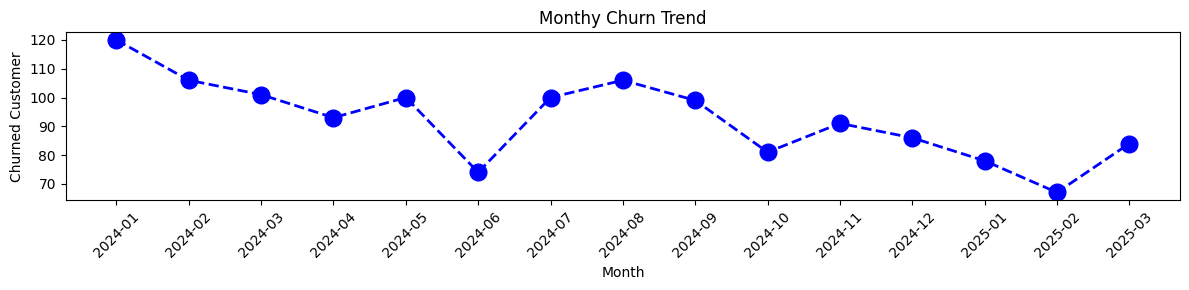

In [49]:
# 4.1 Monthly churn rate (Time series kpi)

df_visual['cancellation_month'] = df_visual['cancellation_date'].dt.to_period('M')

churn_trend = df_visual[df_visual['churn_flag']==1].groupby('cancellation_month').size()

plt.figure(figsize=(12,3))
plt.plot(churn_trend.index.astype('str'), churn_trend.values,marker='o', 
         linestyle='dashed', linewidth = 2, markersize = 12, color='blue')
plt.title('Monthy Churn Trend')
plt.xlabel('Month')
plt.ylabel('Churned Customer')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 4.2 Churned Customers by Plan Type

This visualization compares the churn rate across different subscription plans to identify which plan type has the highest customer churn.

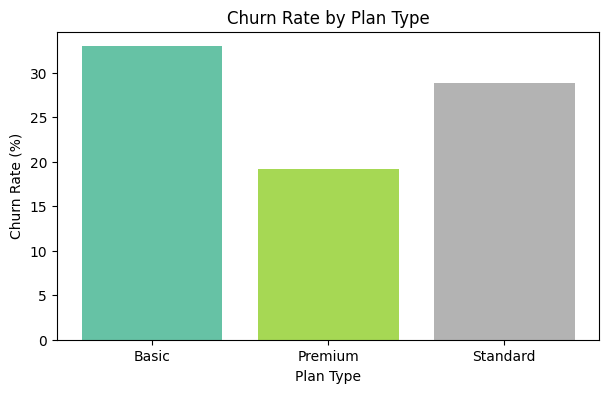

In [50]:
# 4.2 churned by plan type

churn_plan = df_visual.groupby('plan_type')['churn_flag'].mean().mul(100)

# colors = ['Red', 'Blue', 'Purple']

colors = plt.cm.Set2(np.linspace(0,1,len(churn_plan)))

plt.figure(figsize=(7,4))

plt.bar(churn_plan.index , churn_plan.values,color = colors )
plt.title('Churn Rate by Plan Type')
plt.xlabel('Plan Type')
plt.ylabel('Churn Rate (%)')
plt.show()

## 4.4 Churn Rate by Subscription Type

This visualization compares customer churn rates across different subscription types to identify which acquisition channel has higher customer churn.

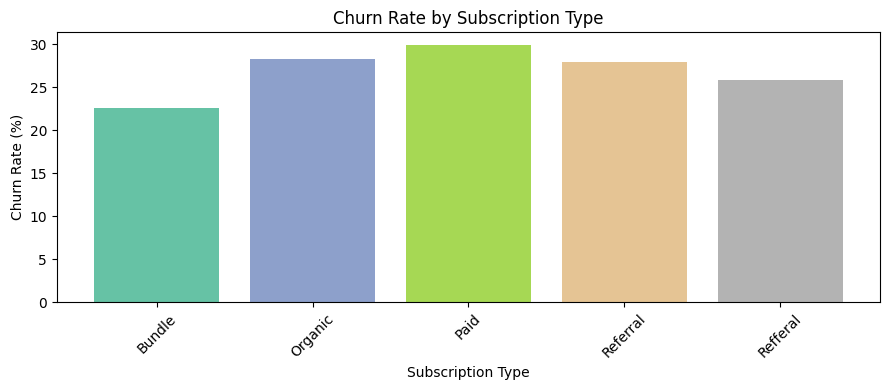

In [51]:
# 4.4 Churn by subscription type

churn_subscription = df_visual.groupby('subscription_type')['churn_flag'].mean().mul(100)

colors = plt.cm.Set2(np.linspace(0, 1, len(churn_subscription)))

plt.figure(figsize=(9, 4))

plt.bar(churn_subscription.index, churn_subscription.values, color=colors)

plt.title('Churn Rate by Subscription Type')
plt.xlabel('Subscription Type')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## 4.3 Churn Rate by State

This visualization compares customer churn rates across different states to identify geographical patterns in customer churn.

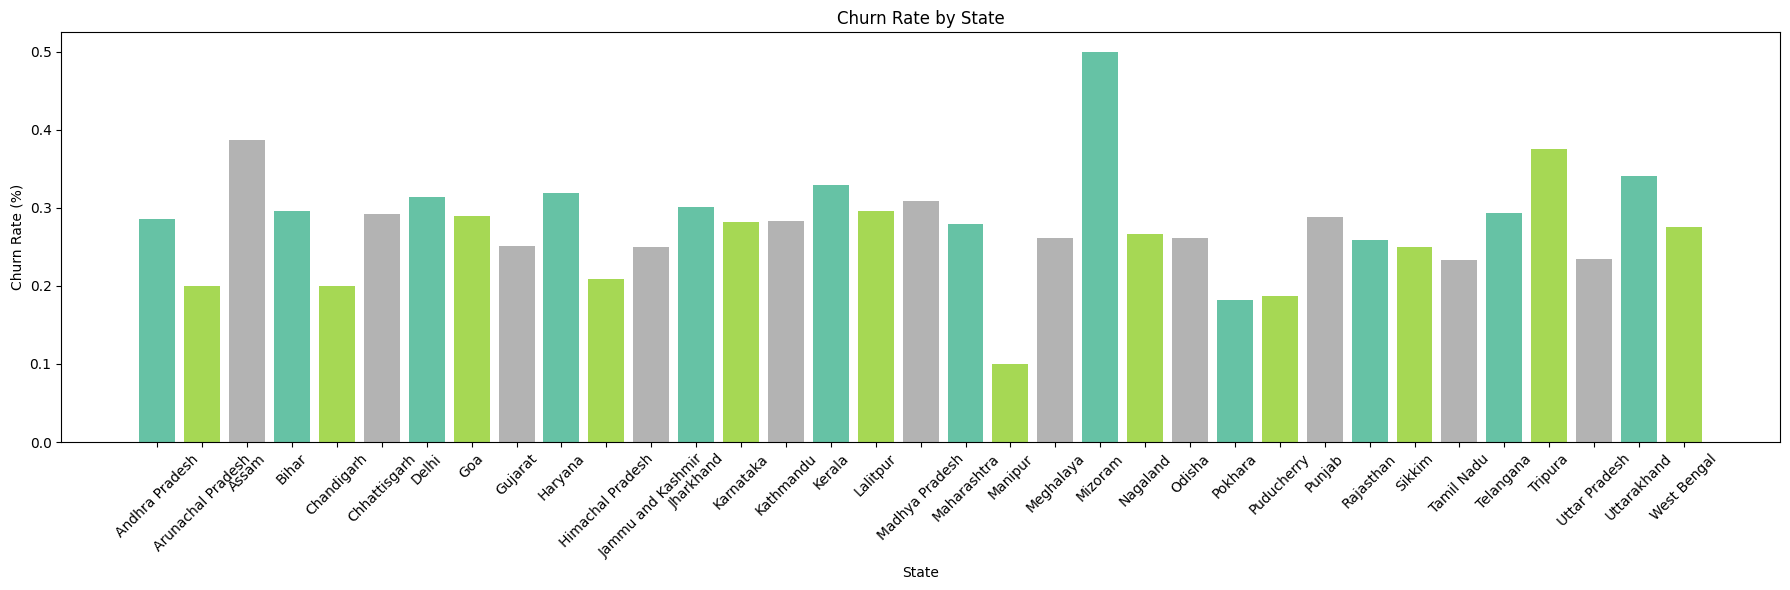

In [52]:
# 4.3 Churn By state

# 4.2 churned by plan type

churn_state = df_visual.groupby('state')['churn_flag'].mean()

# colors = ['Red', 'Blue', 'Purple']

colors = plt.cm.Set2(np.linspace(0,1,len(churn_plan)))

plt.figure(figsize=(18,6))

plt.bar(churn_state.index , churn_state.values,color = colors )
plt.title('Churn Rate by State')
plt.xlabel('State')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [53]:
# Visualization using seaborn

In [54]:
#Encoding
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_count', 'escalations', 'csat_score', 'comment',
       'tenure_days', 'churn_risk', 'cancellation_month'],
      dtype='object')

In [55]:
# df_encoded = 
df_visual[['plan_type', 'contract_type','churn_score',
           'churn_flag', 'escalations', 'churn_risk' ]].head()

,plan_type,contract_type,churn_score,churn_flag,escalations,churn_risk
0,Standard,Annual,12,0,NaN,low
1,Premium,Annual,91,1,1.0,high
2,Basic,Monthly,34,0,NaN,low
3,Premium,Annual,8,0,NaN,low
4,Standard,Monthly,88,1,1.0,high


In [56]:
import warnings
warnings.filterwarnings('ignore')

# Incorrect method of encoding - as numbers are not assigned based on priority

df_encoded = df_visual[
    ['plan_type', 'contract_type', 'churn_score',
     'churn_flag', 'escalations', 'churn_risk']
].copy()

categorical_cols = ['plan_type', 'contract_type', 'churn_risk']

for col in categorical_cols:
    df_encoded[col] = df_encoded[col].astype('category').cat.codes

In [57]:
df_encoded.head()

,plan_type,contract_type,churn_score,churn_flag,escalations,churn_risk
0,2,0,12,0,NaN,1
1,1,0,91,1,1.0,0
2,0,1,34,0,NaN,1
3,1,0,8,0,NaN,1
4,2,1,88,1,1.0,0


<Axes: >

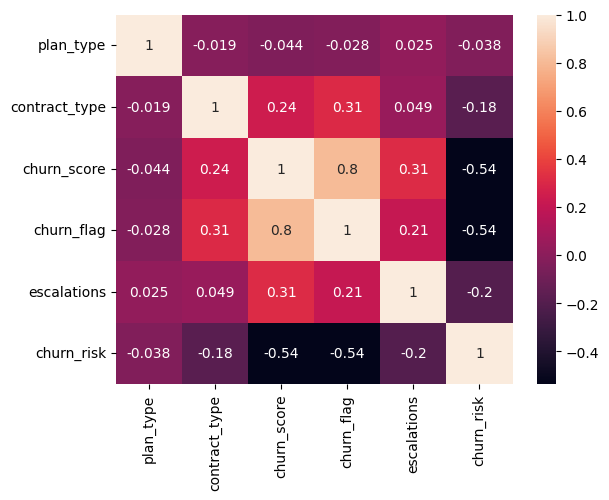

In [58]:
# HeatMap (correlation matrix)

sns.heatmap(df_encoded.corr(), annot=True)

## 5.2 Correct Encoding Method

In this section, categorical variables are encoded using manually assigned numerical values to maintain a consistent and meaningful category order.

In [59]:
# Correct method of encoding

df_encoded = df_visual[
    ['plan_type', 'contract_type', 'churn_score',
     'churn_flag', 'escalations', 'churn_risk']
].copy()

df_encoded['plan_type'] = df_encoded['plan_type'].map({
    'Basic': 0,
    'Standard': 1,
    'Premium': 2
})

df_encoded['contract_type'] = df_encoded['contract_type'].map({
    'Monthly': 0,
    'Annual': 1
})

df_encoded['churn_risk'] = df_encoded['churn_risk'].map({
    'low': 0,
    'med': 1,
    'high': 2
})

df_encoded.head()

,plan_type,contract_type,churn_score,churn_flag,escalations,churn_risk
0,1,1,12,0,NaN,0
1,2,1,91,1,1.0,2
2,0,0,34,0,NaN,0
3,2,1,8,0,NaN,0
4,1,0,88,1,1.0,2


In [60]:
df_encoded.head(5)

,plan_type,contract_type,churn_score,churn_flag,escalations,churn_risk
0,1,1,12,0,NaN,0
1,2,1,91,1,1.0,2
2,0,0,34,0,NaN,0
3,2,1,8,0,NaN,0
4,1,0,88,1,1.0,2


## 5.3 Correlation Heatmap

A correlation heatmap visualizes the relationships between numerical variables. It helps identify positive and negative correlations among customer churn-related features.

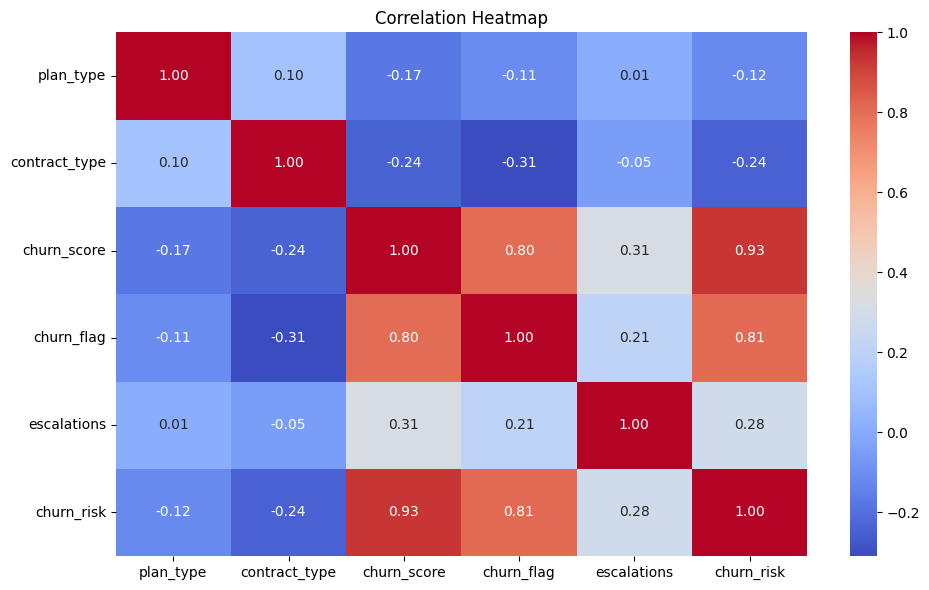

In [61]:
# 5.3 Correlation heatmap

plt.figure(figsize=(10, 6))

sns.heatmap(
    df_encoded.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

## 5.4 Pairplot

A pairplot visualizes pairwise relationships between numerical variables. It helps identify patterns, distributions, and relationships among customer churn-related features.

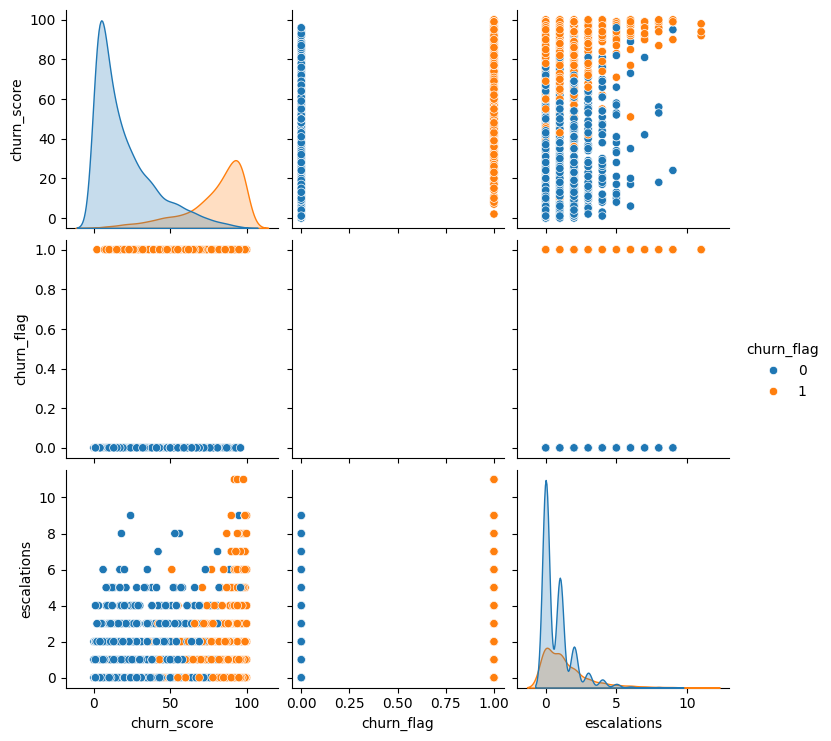

In [62]:
# 5.4 Pairplot

sns.pairplot(
    df_encoded,
    vars=['churn_score', 'churn_flag', 'escalations'],
    hue='churn_flag'
)

plt.show()

## 5.5 Categorical FacetGrid Chart

This visualization compares monthly charges across different plan types and genders, while separating customers by churn-risk category. It helps explore multiple customer attributes together.

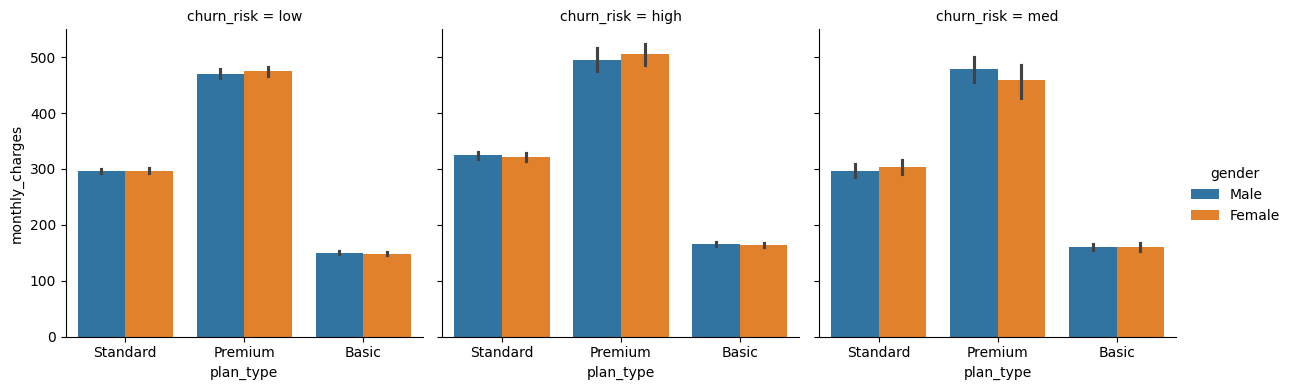

In [63]:
# 5.5 Categorical/facetgrid chart - multi dimension comparison

sns.catplot(
    data=df_visual,
    x='plan_type',
    y='monthly_charges',
    hue='gender',
    col='churn_risk',
    kind='bar',
    height=4,
    aspect=1
)

plt.show()

## 5.6 Pivot Table Analysis

A pivot table summarizes churn rates across different plan types. It helps compare customer churn patterns in a structured tabular format.

In [64]:
# Pivot Table

pd.pivot_table(
    df_visual,
    index='plan_type',
    values='churn_flag',
    aggfunc='mean'
).reset_index()

,plan_type,churn_flag
0,Basic,0.329583
1,Premium,0.191803
2,Standard,0.288233


## 5.7 Customer and Revenue Summary by Plan Type

This summary compares different plan types based on total monthly charges, number of unique customers, and average churn rate. It helps identify which plans contribute more revenue and have higher customer churn.

In [65]:
# Customer and Revenue Summary by Plan Type

pd.pivot_table(
    df_visual,
    index='plan_type',
    values=['monthly_charges', 'customerid', 'churn_flag'],
    aggfunc={
        'monthly_charges': 'sum',
        'customerid': 'nunique',
        'churn_flag': 'mean'
    }
).reset_index()

,plan_type,churn_flag,customerid,monthly_charges
0,Basic,0.329583,1511,233677.95
1,Premium,0.191803,1220,580643.93
2,Standard,0.288233,2269,688385.91
